In [1]:
import os
import numpy as np
import torch
import requests
from collections import Counter
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, accuracy_score

from federated_server import fit_efdpc, predict_efdpc
from utils.utils_dataset import prepare_non_iid_federated_dataset_for_clustering

os.makedirs(".datasets", exist_ok=True)

def download(fname):
    path = os.path.join(".datasets", fname)
    if not os.path.exists(path):
        open(path, "wb").write(requests.get("http://cs.uef.fi/sipu/datasets/" + fname, timeout=30).content)
    return path

def evaluate(labels, y):
    mapping = {g: Counter(y[labels == g]).most_common(1)[0][0] for g in np.unique(labels)}
    y_pred = np.array([mapping[g] for g in labels])
    return accuracy_score(y, y_pred), adjusted_rand_score(y, y_pred), normalized_mutual_info_score(y, y_pred)

skewed (peaks):  ACC=0.780  ARI=0.676  NMI=0.771
skewed (groups):  ACC=0.805  ARI=0.723  NMI=0.812


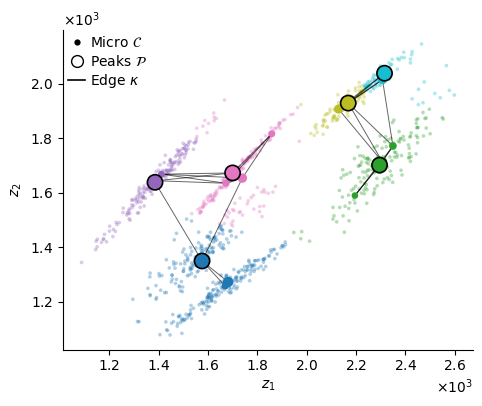

Aggregation (peaks):  ACC=0.949  ARI=0.887  NMI=0.902
Aggregation (groups):  ACC=0.961  ARI=0.920  NMI=0.914


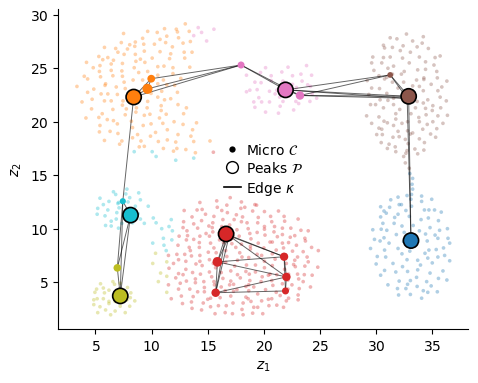

R15 (peaks):  ACC=0.997  ARI=0.993  NMI=0.994
R15 (groups):  ACC=0.997  ARI=0.993  NMI=0.994


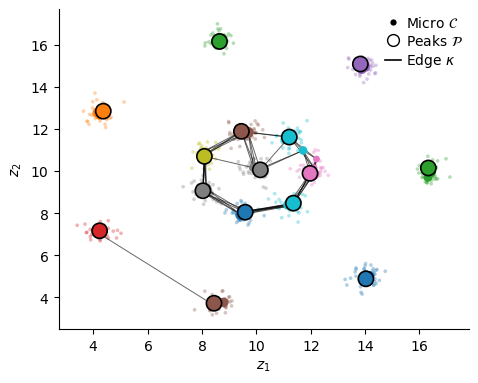

D31 (peaks):  ACC=0.973  ARI=0.945  NMI=0.963
D31 (groups):  ACC=0.969  ARI=0.938  NMI=0.960


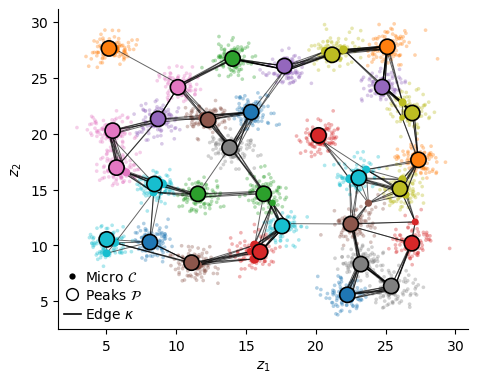

In [2]:
datasets = [("skewed", 6), ("Aggregation", 7), ("R15", 15), ("D31", 31)]

for name, num_clusters in datasets:
    if name == "skewed":
        X = np.loadtxt(download(name + ".txt"))
        y = np.loadtxt(download(name + ".pa"), skiprows=4).astype(int) - 1
    else:
        data = np.loadtxt(download(name + ".txt"))
        X, y = data[:, :2], data[:, 2].astype(int) - 1

    torch.manual_seed(0)
    np.random.seed(0)
    _, train_datasets, *_ = prepare_non_iid_federated_dataset_for_clustering(
        torch.tensor(X, dtype=torch.float32), torch.tensor(y), num_clients=3, alpha=0.9)
    client_data = [ds.tensors[0].numpy() for ds in train_datasets]

    model = fit_efdpc(client_data, P=num_clusters)
    labels = predict_efdpc(model, X)

    for variant in ("peaks", "groups"):
        acc, ari, nmi = evaluate(labels[variant], y)
        print(f"{name} ({variant}):  ACC={acc:.3f}  ARI={ari:.3f}  NMI={nmi:.3f}")
    model.hierarch.plot_all_cluster_groupings(data=X)

In [3]:
from sklearn.datasets import make_blobs

X, y = make_blobs(n_samples=20000, n_features=2000, centers=10,
                  cluster_std=np.random.default_rng(0).uniform(1, 4, 10), random_state=0)
X = X.astype(np.float32)

torch.manual_seed(0)
np.random.seed(0)
_, train_datasets, *_ = prepare_non_iid_federated_dataset_for_clustering(
    torch.tensor(X), torch.tensor(y), num_clients=5, alpha=0.9)
client_data = [ds.tensors[0].numpy() for ds in train_datasets]

model = fit_efdpc(client_data, P=10)
labels = predict_efdpc(model, X)

for variant in ("peaks", "groups"):
    acc, ari, nmi = evaluate(labels[variant], y)
    print(f"blobs d=2000 ({variant}):  ACC={acc:.3f}  ARI={ari:.3f}  NMI={nmi:.3f}")

blobs d=2000 (peaks):  ACC=1.000  ARI=1.000  NMI=1.000
blobs d=2000 (groups):  ACC=1.000  ARI=1.000  NMI=1.000
